In [1]:
print("Welcome to SmartStock")


Welcome to SmartStock


In [3]:
from pathlib import Path

project_folder = Path.home() / "Desktop" / "SmartStock project"
data_folder = project_folder / "data" / "raw"
print("Project folder:", project_folder)
print("Raw data folder:", data_folder)
print("Does the raw data folder exist?", data_folder.exists())

Project folder: C:\Users\user\Desktop\SmartStock project
Raw data folder: C:\Users\user\Desktop\SmartStock project\data\raw
Does the raw data folder exist? False


In [4]:
from pathlib import Path

project_folder = Path.home() / "Desktop" / "SmartStock project"

print("Does the project folder exist?", project_folder.exists())
print("Items inside the project folder:")

for item in project_folder.iterdir():
    print(item.name)

Does the project folder exist? True
Items inside the project folder:
data
notebooks
SmartStock_Sample_Data_README.txt


In [5]:
data_folder = project_folder / "data"
print("Items inside the data folder:")
for item in data_folder.iterdir():
    print(item.name)

Items inside the data folder:
raw


In [6]:
raw_folder = project_folder / "data" / "raw"
print("Files inside the raw folder:")
for item in raw_folder.iterdir():
    print(item.name)

Files inside the raw folder:
inventory.csv
products.csv
sales.csv


In [9]:
import pandas as pd
sales_file = raw_folder / "sales.csv"
sales = pd.read_csv(sales_file)
sales.head()

NameError: name 'raw_folder' is not defined

In [8]:
print("Number of rows:", sales.shape[0])
print("Number of columns:", sales.shape[1])

Number of rows: 1205
Number of columns: 7


In [9]:
print(sales.columns.tolist())

['sale_line_id', 'order_id', 'order_date', 'product_id', 'quantity', 'unit_price', 'unit_cost']


In [10]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sale_line_id  1204 non-null   object 
 1   order_id      1205 non-null   object 
 2   order_date    1204 non-null   object 
 3   product_id    1204 non-null   object 
 4   quantity      1204 non-null   float64
 5   unit_price    1204 non-null   float64
 6   unit_cost     1205 non-null   float64
dtypes: float64(3), object(4)
memory usage: 66.0+ KB


In [11]:
sales.isnull().sum()

sale_line_id    1
order_id        0
order_date      1
product_id      1
quantity        1
unit_price      1
unit_cost       0
dtype: int64

In [13]:
print("Number of duplicate rows:", sales.duplicated().sum())

Number of duplicate rows: 5


In [14]:
sales[sales.duplicated(keep=False)]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
17,SL00018,ORD10377,2026-08-15,P040,7.0,197.27,139.83
108,SL00109,ORD10605,2026-09-02,P031,7.0,179.54,103.97
333,SL00334,ORD10134,2026-06-09,P027,6.0,247.79,178.05
702,SL00703,ORD10700,2026-04-23,P033,4.0,72.67,49.96
1001,SL01002,ORD10626,2026-08-20,P035,3.0,30.94,17.78
1200,SL00018,ORD10377,2026-08-15,P040,7.0,197.27,139.83
1201,SL00109,ORD10605,2026-09-02,P031,7.0,179.54,103.97
1202,SL00334,ORD10134,2026-06-09,P027,6.0,247.79,178.05
1203,SL00703,ORD10700,2026-04-23,P033,4.0,72.67,49.96
1204,SL01002,ORD10626,2026-08-20,P035,3.0,30.94,17.78


In [15]:
sales_clean = sales.drop_duplicates().copy()
print("Original rows:", len(sales))
print("Rows after removing duplicates:", len(sales_clean))
print("Duplicate rows remaining:", sales_clean.duplicated().sum())

Original rows: 1205
Rows after removing duplicates: 1200
Duplicate rows remaining: 0


In [16]:
sales_clean[sales_clean["quantity"] <= 0]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
350,SL00351,ORD10744,2026-08-02,P031,-2.0,180.01,103.97


In [17]:
sales_clean[sales_clean["quantity"] <= 0][
["sale_line_id", "order_id", "order_date", "product_id", "quantity", "unit_price"]]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price
350,SL00351,ORD10744,2026-08-02,P031,-2.0,180.01


In [18]:
sales_clean[sales_clean["quantity"] < 0]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
350,SL00351,ORD10744,2026-08-02,P031,-2.0,180.01,103.97


In [19]:
sales_clean[sales_clean["order_id"] == "ord10744"]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost


In [20]:
sales_clean["order_id"].dtype

dtype('O')

In [21]:
sales_clean["order_id"].head()

0    ORD10657
1    ORD10124
2    ORD10587
3    ORD10559
4    ORD10696
Name: order_id, dtype: object

In [22]:
sales_clean[sales_clean["order_id"] == "ORD10744"]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
350,SL00351,ORD10744,2026-08-02,P031,-2.0,180.01,103.97
1078,SL01079,ORD10744,2026-07-27,P020,6.0,113.81,70.88


In [25]:
sales_clean[sales_clean["order_id"] =="ORD10744"].T

,350,1078
sale_line_id,SL00351,SL01079
order_id,ORD10744,ORD10744
order_date,2026-08-02,2026-07-27
product_id,P031,P020
quantity,-2.0,6.0
unit_price,180.01,113.81
unit_cost,103.97,70.88


In [26]:
sales_clean[sales_clean["quantity"] < 0].shape[0]

1

In [27]:
sales_clean.isnull().sum()

sale_line_id    1
order_id        0
order_date      1
product_id      1
quantity        1
unit_price      1
unit_cost       0
dtype: int64

In [29]:
sales_clean[sales_clean.isnull().any(axis=1)]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
120,SL00121,ORD10508,2026-04-11,NaN,2.0,110.62,87.24
430,SL00431,ORD10433,2026-05-31,P016,2.0,NaN,108.08
540,NaN,ORD10121,2026-08-29,P019,5.0,124.85,97.24
610,SL00611,ORD10170,NaN,P020,3.0,104.93,70.88
820,SL00821,ORD10326,2026-04-06,P002,NaN,44.28,26.85


In [30]:
sales_clean[sales_clean.isnull().any(axis=1)].isnull()

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
120,False,False,False,True,False,False,False
430,False,False,False,False,False,True,False
540,True,False,False,False,False,False,False
610,False,False,True,False,False,False,False
820,False,False,False,False,True,False,False


In [33]:
(sales_clean.isnull().sum() / len(sales_clean) * 100).round(2)

sale_line_id    0.08
order_id        0.00
order_date      0.08
product_id      0.08
quantity        0.08
unit_price      0.08
unit_cost       0.00
dtype: float64

In [34]:
sales_analysis = sales_clean.copy()

In [35]:
sales_analysis.shape

(1200, 7)

In [36]:
sales_analysis[sales_analysis.isnull().any(axis=1)]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
120,SL00121,ORD10508,2026-04-11,NaN,2.0,110.62,87.24
430,SL00431,ORD10433,2026-05-31,P016,2.0,NaN,108.08
540,NaN,ORD10121,2026-08-29,P019,5.0,124.85,97.24
610,SL00611,ORD10170,NaN,P020,3.0,104.93,70.88
820,SL00821,ORD10326,2026-04-06,P002,NaN,44.28,26.85


In [37]:
sales_analysis[sales_analysis["order_id"] == "ORD10508"]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
120,SL00121,ORD10508,2026-04-11,NaN,2.0,110.62,87.24
1036,SL01037,ORD10508,2026-04-16,P033,1.0,73.38,49.96


In [38]:
sales_analysis[sales_analysis["order_id"] == "ORD10508"].T

,120,1036
sale_line_id,SL00121,SL01037
order_id,ORD10508,ORD10508
order_date,2026-04-11,2026-04-16
product_id,NaN,P033
quantity,2.0,1.0
unit_price,110.62,73.38
unit_cost,87.24,49.96


In [39]:
sales_analysis[sales_analysis["product_id"] == "P033"]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
23,SL00024,ORD10264,2026-07-17,P033,8.0,72.99,49.96
25,SL00026,ORD10547,2026-09-19,P033,7.0,69.62,49.96
65,SL00066,ORD10218,2026-07-09,P033,2.0,66.94,49.96
101,SL00102,ORD10175,2026-07-16,P033,6.0,72.62,49.96
145,SL00146,ORD10583,2026-06-23,P033,1.0,71.09,49.96
218,SL00219,ORD10286,2026-07-26,P033,4.0,75.27,49.96
234,SL00235,ORD10798,2026-09-22,P033,5.0,67.54,49.96
277,SL00278,ORD10479,2026-05-19,P033,8.0,73.91,49.96
314,SL00315,ORD10168,2026-05-10,P033,3.0,70.85,49.96
327,SL00328,ORD10168,2026-04-15,P033,8.0,73.60,49.96


In [40]:
sales_analysis[sales_analysis["order_id"] == "ORD10508"]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
120,SL00121,ORD10508,2026-04-11,NaN,2.0,110.62,87.24
1036,SL01037,ORD10508,2026-04-16,P033,1.0,73.38,49.96


In [41]:
sales_analysis[
    (sales_analysis["order_id"] == "ORD10508") &
    (sales_analysis["product_id"].isna())
    ]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
120,SL00121,ORD10508,2026-04-11,NaN,2.0,110.62,87.24


In [42]:
%whos

Variable               Type             Data/Info
-------------------------------------------------
NamespaceMagics        MetaHasTraits    <class 'IPython.core.magi<...>mespace.NamespaceMagics'>
Path                   type             <class 'pathlib._local.Path'>
collections            module           <module 'collections' fro<...>ollections\\__init__.py'>
data_folder            WindowsPath      C:\Users\user\Desktop\SmartStock project\data
dataframe_columns      function         <function dataframe_colum<...>ns at 0x0000014664E63920>
dataframe_hash         function         <function dataframe_hash at 0x0000014664F6D440>
dtypes_str             function         <function dtypes_str at 0x0000014664F6D120>
get_dataframes         function         <function get_dataframes at 0x0000014664F6E200>
get_ipython            function         <function get_ipython at 0x000001465F2E8C20>
getpass                module           <module 'getpass' from 'C<...>conda3\\Lib\\getpass.py'>
hashlib        

In [43]:
import os 
os.listdir("..")

['data', 'notebooks', 'SmartStock_Sample_Data_README.txt']

In [44]:
os.listdir("../Data")

['raw']

In [45]:
os.listdir("../Data/raw")

['inventory.csv', 'products.csv', 'sales.csv']

In [46]:
products = pd.read_csv("../Data/raw/product.csv")
products.head()

FileNotFoundError: [Errno 2] No such file or directory: '../Data/raw/product.csv'

In [47]:
import os
print("Current folder:", os.getcwd())
print("Files in raw folder:",os.listdir("../Data/raw"))

Current folder: C:\Users\user\Desktop\SmartStock Project\notebooks
Files in raw folder: ['inventory.csv', 'products.csv', 'sales.csv']


In [49]:
import os
for root, dirs, files in os.walk(".."):
    for file in files:
        if file.lower().startswith(("product", "sales", "inventory")):
            print(os.path.join(root, file))

..\data\raw\inventory.csv
..\data\raw\products.csv
..\data\raw\sales.csv


In [51]:
products = pd.read_csv("../data/raw/product.csv")
print(products.shape)
display(products.head())

FileNotFoundError: [Errno 2] No such file or directory: '../data/raw/product.csv'

In [21]:
sales_clean["order_id"].head()

0    ORD10657
1    ORD10124
2    ORD10587
3    ORD10559
4    ORD10696
Name: order_id, dtype: object

In [53]:
import os
for root, dirs, files in os.walk(".."):
    for file in files:
        if file.lower().startswith("product"):
            product_path = os.path.join(root, file)
            print("Exact product file path:", repr(product_path))

Exact product file path: '..\\data\\raw\\products.csv'


In [54]:
products = pd.read_csv("../data/raw/products.csv")
print(products.shape)
display(products.head())

(40, 6)


,product_id,product_name,category,supplier,unit_cost,suggested_unit_price
0,P001,Rice 5kg,Groceries,Tema Supply Hub,69.78,88.45
1,P002,Cooking Oil 1L,Groceries,Westline Distributors,26.85,41.24
2,P003,Tomato Paste,Groceries,Harbour Goods Co,74.01,95.17
3,P004,Canned Sardines,Groceries,Coastal Wholesale Ltd,23.59,32.64
4,P005,Spaghetti 500g,Groceries,Harbour Goods Co,39.25,48.65


In [55]:
products[products["product_id"] == "P033"]

,product_id,product_name,category,supplier,unit_cost,suggested_unit_price
32,P033,Exercise Books Pack,Stationery,Tema Supply Hub,49.96,69.82


In [56]:
sales_analysis[
    (sales_analysis["order_id"] == "ORD10508")
    ].T

,120,1036
sale_line_id,SL00121,SL01037
order_id,ORD10508,ORD10508
order_date,2026-04-11,2026-04-16
product_id,NaN,P033
quantity,2.0,1.0
unit_price,110.62,73.38
unit_cost,87.24,49.96


In [57]:
sales_analysis[sales_analysis.isnull().any(axis=1)]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
120,SL00121,ORD10508,2026-04-11,NaN,2.0,110.62,87.24
430,SL00431,ORD10433,2026-05-31,P016,2.0,NaN,108.08
540,NaN,ORD10121,2026-08-29,P019,5.0,124.85,97.24
610,SL00611,ORD10170,NaN,P020,3.0,104.93,70.88
820,SL00821,ORD10326,2026-04-06,P002,NaN,44.28,26.85


In [58]:
sales_analysis.isnull().sum()

sale_line_id    1
order_id        0
order_date      1
product_id      1
quantity        1
unit_price      1
unit_cost       0
dtype: int64

In [60]:
sales_analysis[sales_analysis.isnull().any(axis=1)].sort_values("order_id")

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
540,NaN,ORD10121,2026-08-29,P019,5.0,124.85,97.24
610,SL00611,ORD10170,NaN,P020,3.0,104.93,70.88
820,SL00821,ORD10326,2026-04-06,P002,NaN,44.28,26.85
430,SL00431,ORD10433,2026-05-31,P016,2.0,NaN,108.08
120,SL00121,ORD10508,2026-04-11,NaN,2.0,110.62,87.24


In [61]:
sales_analysis.isnull().sum()

sale_line_id    1
order_id        0
order_date      1
product_id      1
quantity        1
unit_price      1
unit_cost       0
dtype: int64

In [62]:
sales_clean = sales_analysis.dropna(
    subset=["order_date", "product_id", "quantity", "unit_price"]
).copy()
print("Original rows:", len(sales_analysis))
print("Rows after cleaning:", len(sales_clean))
print("Rows removed:", len(sales_analysis) - len(sales_clean))
print("Remaining missing values:")
print(sales_clean.isnull().sum())

Original rows: 1200
Rows after cleaning: 1196
Rows removed: 4
Remaining missing values:
sale_line_id    1
order_id        0
order_date      0
product_id      0
quantity        0
unit_price      0
unit_cost       0
dtype: int64


In [63]:
sales_clean[sales_clean["quantity"] < 0]

,sale_line_id,order_id,order_date,product_id,quantity,unit_price,unit_cost
350,SL00351,ORD10744,2026-08-02,P031,-2.0,180.01,103.97


In [64]:
sales_clean[sales_clean["quantity"] < 0].T

,350
sale_line_id,SL00351
order_id,ORD10744
order_date,2026-08-02
product_id,P031
quantity,-2.0
unit_price,180.01
unit_cost,103.97


In [65]:
sales_clean["revenue"] = (
    sales_clean["quantity"] * sales_clean["unit_price"]
)
sales_clean["total_cost"] = (
    sales_clean["quantity"] * sales_clean["unit_cost"]
)
sales_clean["profit"] = (
    sales_clean["revenue"] - sales_clean["total_cost"]
)
sales_clean[
    ["order_id", "product_id", "quantity", "unit_price", "revenue", "total_cost", "profit"]
    ].head()

,order_id,product_id,quantity,unit_price,revenue,total_cost,profit
0,ORD10657,P002,7.0,41.02,287.14,187.95,99.19
1,ORD10124,P027,1.0,239.21,239.21,178.05,61.16
2,ORD10587,P034,5.0,97.14,485.70,361.55,124.15
3,ORD10559,P016,4.0,147.51,590.04,432.32,157.72
4,ORD10696,P018,5.0,32.32,161.60,107.45,54.15


In [66]:
total_revenue = sales_clean["revenue"].sum()
total_cost = sales_clean["total_cost"].sum()
total_profit = sales_clean["profit"].sum()

profit_margin = (total_profit / total_revenue) * 100

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Cost: {total_cost:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")

Total Revenue: 639,548.57
Total Cost: 449,342.59
Total Profit: 190,205.98
Profit Margin: 29.74%


In [67]:
product_performance = (
    sales_clean.groupby("product_id")
    .agg(
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        profit=("profit", "sum")
    )
    .sort_values("revenue", ascending=False)
)
product_performance.head(5)

,units_sold,revenue,total_cost,profit
product_id,,,,
P013,181.0,45971.35,31242.41,14728.94
P027,157.0,37378.52,27953.85,9424.67
P023,139.0,32853.43,20455.24,12398.19
P026,156.0,30762.21,24087.96,6674.25
P040,147.0,28333.90,20555.01,7778.89


In [68]:
print(product_performance.head(5).to_string())

            units_sold   revenue  total_cost    profit
product_id                                            
P013             181.0  45971.35    31242.41  14728.94
P027             157.0  37378.52    27953.85   9424.67
P023             139.0  32853.43    20455.24  12398.19
P026             156.0  30762.21    24087.96   6674.25
P040             147.0  28333.90    20555.01   7778.89


In [69]:
product_performance.sort_values(
    "profit", ascending=False
).head(5).round(2)

,units_sold,revenue,total_cost,profit
product_id,,,,
P013,181.0,45971.35,31242.41,14728.94
P023,139.0,32853.43,20455.24,12398.19
P008,121.0,25652.51,15569.07,10083.44
P027,157.0,37378.52,27953.85,9424.67
P031,131.0,22472.19,13620.07,8852.12


In [70]:
top_products = (
    product_performance
    .sort_values("profit", ascending=False)
    .head(5)
    .reset_index()
    .merge(products, on="product_id", how="left")
)
top_products[
    ["product_id", "product_name", "units_sold", "revenue", "profit"]
    ].round(2)

,product_id,product_name,units_sold,revenue,profit
0,P013,Toilet Tissue Pack,181.0,45971.35,14728.94
1,P023,Toothpaste,139.0,32853.43,12398.19
2,P008,Bottled Water,121.0,25652.51,10083.44
3,P027,Hand Sanitiser,157.0,37378.52,9424.67
4,P031,A4 Paper Ream,131.0,22472.19,8852.12


In [71]:
inventory = pd.read_csv("../data/raw/inventory.csv")

print("Inventory shape:", inventory.shape)
display(inventory.head())

Inventory shape: (40, 4)


,product_id,stock_on_hand,reorder_level,last_restock_date
0,P001,65.0,17,2026-09-23
1,P002,68.0,21,2026-07-13
2,P003,46.0,7,2026-07-07
3,P004,32.0,7,2026-08-04
4,P005,42.0,9,2026-07-26


In [73]:
inventory["stock_status"] = inventory.apply(
    lambda row: "Reorder"
    if row["stock_on_hand"] <= row["reorder_level"]
    else "Sufficient",
    axis=1
)
inventory["stock_status"].value_counts()

stock_status
Sufficient    34
Reorder        6
Name: count, dtype: int64

In [74]:
low_stock = (
    inventory[inventory["stock_status"] == "Reorder"]
    .merge(products, on="product_id", how="left")
)
low_stock[
    ["product_id", "product_name", "stock_on_hand", "reorder_level"]
    ].sort_values("stock_on_hand")

,product_id,product_name,stock_on_hand,reorder_level
1,P022,Shampoo 400ml,1.0,11
2,P024,Toothbrush Pack,2.0,10
5,P036,Sticky Notes,2.0,6
0,P019,Air Freshener,3.0,11
3,P026,Sanitary Pads,3.0,17
4,P030,Face Wash,20.0,20


In [76]:
print("Total units in stock:", inventory["stock_on_hand"].sum())
print("Products needing reorder:",
    (inventory["stock_status"] == "Reorder").sum())
print("Average stock per product:", 
      round(inventory["stock_on_hand"].mean(), 2))
print("Total units below reorderlevel:",
      (inventory["reorder_level"] - inventory["stock_on_hand"])
      .clip(lower=0).sum())

Total units in stock: 1434.0
Products needing reorder: 6
Average stock per product: 36.77
Total units below reorderlevel: 44.0


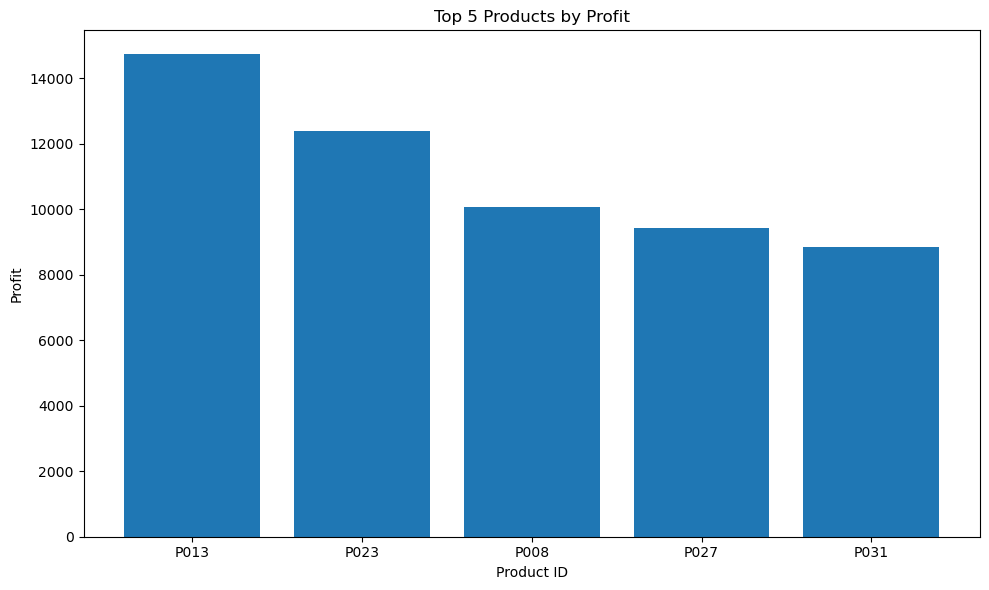

In [80]:
import matplotlib.pyplot as plt

top_profit = (
    product_performance
    .sort_values("profit", ascending=False)
    .head(5)
    .reset_index()
)
plt.figure(figsize=(10, 6))
plt.bar(top_profit["product_id"], top_profit["profit"])
plt.title("Top 5 Products by Profit")
plt.xlabel("Product ID")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

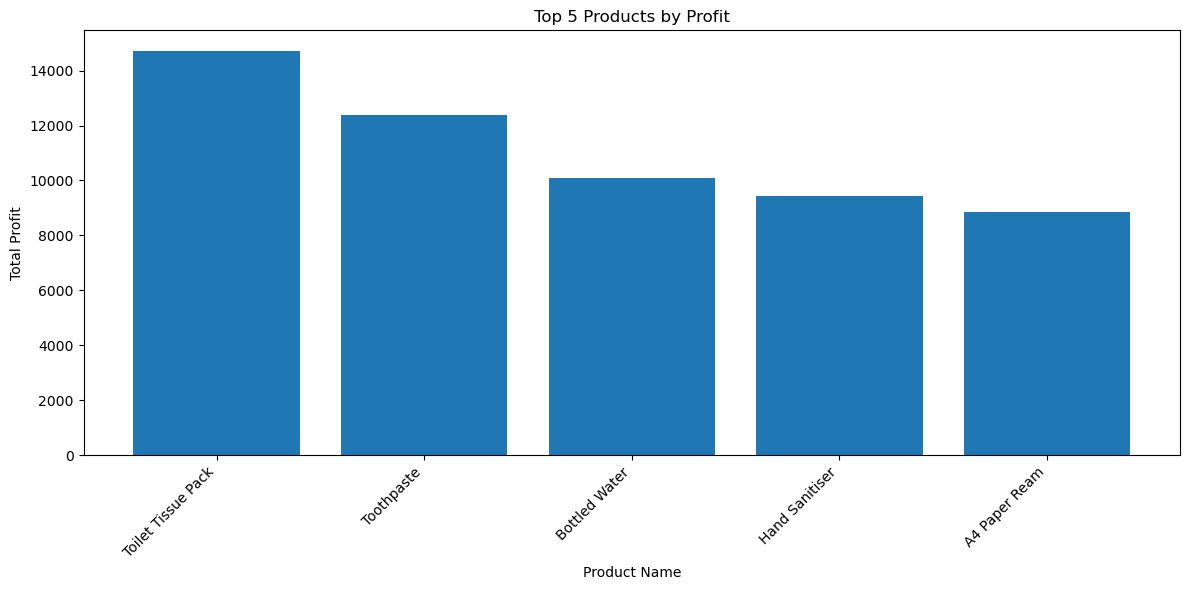

In [81]:
top_profit_named = top_profit.merge(
    products[["product_id", "product_name"]],
    on="product_id",
    how="left"
)
plt.figure(figsize=(12, 6))
plt.bar(
    top_profit_named["product_name"],
    top_profit_named["profit"]
)
plt.title("Top 5 Products by Profit")
plt.xlabel("Product Name")
plt.ylabel("Total Profit")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


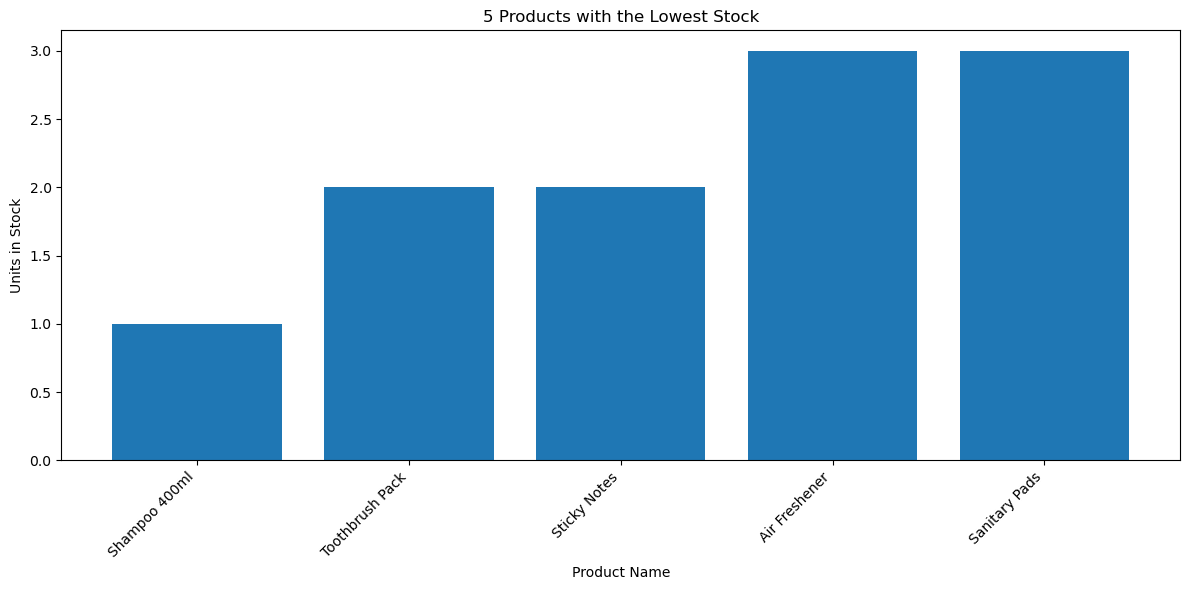

In [83]:
lowest_stock = (
    inventory
    .sort_values("stock_on_hand", ascending=True)
    .head(5)
    .reset_index(drop=True)
)

lowest_stock_named = lowest_stock.merge(
    products[["product_id", "product_name"]],
    on="product_id",
    how="left"
)
plt.figure(figsize=(12, 6))
plt.bar(
    lowest_stock_named["product_name"],
    lowest_stock_named["stock_on_hand"]
)
plt.title("5 Products with the Lowest Stock")
plt.xlabel("Product Name")
plt.ylabel("Units in Stock")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [84]:
reorder_products = inventory[
    inventory["stock_on_hand"] <= inventory["reorder_level"]
    ].copy()
reorder_products_named = reorder_products.merge(
    products[["product_id", "product_name"]],
    on="product_id",
    how="left"
)
reorder_products_named = reorder_products_named[
    [
        "product_id",
        "product_name",
        "stock_on_hand",
        "reorder_level"
    ]
    ].sort_values("stock_on_hand")
display(reorder_products_named)

,product_id,product_name,stock_on_hand,reorder_level
1,P022,Shampoo 400ml,1.0,11
2,P024,Toothbrush Pack,2.0,10
5,P036,Sticky Notes,2.0,6
0,P019,Air Freshener,3.0,11
3,P026,Sanitary Pads,3.0,17
4,P030,Face Wash,20.0,20


In [87]:
reorder_products_named["units_to_reorder"] = (
    reorder_products_named["reorder_level"]
    - reorder_products_named["stock_on_hand"]
).clip(lower=0)
display(
    reorder_products_named[
        [
            "product_name",
            "stock_on_hand",
            "reorder_level",
            "units_to_reorder"
        ]
        ]
)
print(
     "Total additional units required:",
     reorder_products_named["units_to_reorder"].sum()
 )

,product_name,stock_on_hand,reorder_level,units_to_reorder
1,Shampoo 400ml,1.0,11,10.0
2,Toothbrush Pack,2.0,10,8.0
5,Sticky Notes,2.0,6,4.0
0,Air Freshener,3.0,11,8.0
3,Sanitary Pads,3.0,17,14.0
4,Face Wash,20.0,20,0.0


Total additional units required: 44.0


In [89]:
print("Number of products:", len(inventory))
print(
    "Total stock on hand:",
    inventory["stock_on_hand"].sum()
)
print(
    "Average stock per product:",
    inventory["stock_on_hand"].mean()
)
print(
    "Products needing reorder:",
    (inventory["stock_on_hand"] <= inventory["reorder_level"]).sum()
)
print(
    "Total units below reorder level:",
    (
        inventory["reorder_level"] - inventory["stock_on_hand"]
    ).clip(lower=0).sum()
)

Number of products: 40
Total stock on hand: 1434.0
Average stock per product: 36.76923076923077
Products needing reorder: 6
Total units below reorder level: 44.0


In [8]:
print("Inventory rows:", len(inventory))
print("Unique product IDs:", inventory["product_id"].nunique())
print("Missing stock values:", inventory["stock_on_hand"].isna().sum())

print("\nStock total:", inventory["stock_on_hand"].sum())
print("Stock average:", inventory["stock_on_hand"].mean())
print("Total divided by row count:",
      inventory["stock_on_hand"].sum() /len(inventory())
     )
      
print("\nDuplicate products IDs:",
    inventory["product_id"].duplicated().sum())

NameError: name 'inventory' is not defined

In [4]:
%whos

Variable               Type             Data/Info
-------------------------------------------------
NamespaceMagics        MetaHasTraits    <class 'IPython.core.magi<...>mespace.NamespaceMagics'>
collections            module           <module 'collections' fro<...>ollections\\__init__.py'>
dataframe_columns      function         <function dataframe_colum<...>ns at 0x00000248E2C72F20>
dataframe_hash         function         <function dataframe_hash at 0x00000248E00F7100>
dtypes_str             function         <function dtypes_str at 0x00000248E00F6840>
get_dataframes         function         <function get_dataframes at 0x00000248E2A7F4C0>
get_ipython            function         <function get_ipython at 0x00000248DD2A8C20>
getpass                module           <module 'getpass' from 'C<...>conda3\\Lib\\getpass.py'>
hashlib                module           <module 'hashlib' from 'C<...>conda3\\Lib\\hashlib.py'>
import_pandas_safely   function         <function import_pandas_s<...>ly at

In [10]:
from pathlib import Path
print("Current working folder:", Path.cwd())

Current working folder: C:\Users\user\Desktop\SmartStock Project\notebooks


In [17]:
from pathlib import Path
import pandas as pd

#Locate the SmartStock project folder
project_folder = Path.cwd().parent

#Find the folder containing the CSV data
csv_files = list(project_folder.rglob("*csv"))

if not csv_files:
    print("No CSV found in:",project_folder)
    print("Please check where your CSV files are saved.")
else:
    print:("CSV files found:")
    for file in csv_files:
        print(" -", file.relative_to(project_folder))

        #Restore the raw data folder
        raw_folder = csv_files[0].parent

        #Reload the main datasets if their files exist
        for filename, variable_name in [
            ("sales.csv", "sales"),
            ("products.csv", "products"),
            ("inventory.csv", "inventory"),
        ]:
            file_path = raw_folder / filename
            if file_path.exists():
                globals()[variable_name] = pd.read_csv(file_path)
                print(f"\n{filename} loaded successfully: {globals()[variable_name].shape}")
            else:
                print(f"\n{filename} not found in {raw_folder}")

        print("\nRecovery cell finishes.")

 - data\raw\inventory.csv

sales.csv loaded successfully: (1205, 7)

products.csv loaded successfully: (40, 6)

inventory.csv loaded successfully: (40, 4)

Recovery cell finishes.
 - data\raw\products.csv

sales.csv loaded successfully: (1205, 7)

products.csv loaded successfully: (40, 6)

inventory.csv loaded successfully: (40, 4)

Recovery cell finishes.
 - data\raw\sales.csv

sales.csv loaded successfully: (1205, 7)

products.csv loaded successfully: (40, 6)

inventory.csv loaded successfully: (40, 4)

Recovery cell finishes.


In [18]:
%whos

Variable               Type             Data/Info
-------------------------------------------------
NamespaceMagics        MetaHasTraits    <class 'IPython.core.magi<...>mespace.NamespaceMagics'>
Path                   type             <class 'pathlib._local.Path'>
collections            module           <module 'collections' fro<...>ollections\\__init__.py'>
csv_files              list             n=3
dataframe_columns      function         <function dataframe_colum<...>ns at 0x00000248E303F7E0>
dataframe_hash         function         <function dataframe_hash at 0x00000248E30D7D80>
dtypes_str             function         <function dtypes_str at 0x00000248E30E27A0>
file                   WindowsPath      C:\Users\user\Desktop\Sma<...>roject\data\raw\sales.csv
file_path              WindowsPath      C:\Users\user\Desktop\Sma<...>ct\data\raw\inventory.csv
filename               str              inventory.csv
get_dataframes         function         <function get_dataframes at 0x00000248E2

In [21]:
#Restore the inventory analysis and verify the stock figures

inventory["stock_on_hand"] = pd.to_numeric(
    inventory["stock_on_hand"], errors="coerce"
)
inventory["reorder_level"] = pd.to_numeric(
    inventory["reorder_level"], errors="coerce"
)

print("Inventory rows:", len(inventory))
print("Missing stock values:", inventory["stock_on_hand"].isna().sum())
print("Total stock on hand:", inventory["stock_on_hand"].sum())
print("Average stock per product:", inventory["stock_on_hand"].mean())
print("Products needing reorder:",
      (inventory["stock_on_hand"] <= inventory["reorder_level"]).sum())

print("\nRows with missing stock values:")
display(
    inventory.loc[
        inventory["stock_on_hand"].isna(),
        ["product_id","stock_on_hand", "reorder_level"]
        ]
)

Inventory rows: 40
Missing stock values: 1
Total stock on hand: 1434.0
Average stock per product: 36.76923076923077
Products needing reorder: 6

Rows with missing stock values:


,product_id,stock_on_hand,reorder_level
5,P006,NaN,18


In [23]:
#Inspect the inventory record with the missing stock

inventory[inventory["stock_on_hand"].isna()]

,product_id,stock_on_hand,reorder_level,last_restock_date
5,P006,NaN,18,2026-09-14


In [24]:
original_inventory = pd.read_csv(raw_folder / "inventory.csv")

print("Original CSV stock value for P006:")
display(
    original_inventory.loc[
        original_inventory["product_id"] == "P006",
        ["product_id", "stock_on_hand", "reorder_level"]
        ]
)

Original CSV stock value for P006:


,product_id,stock_on_hand,reorder_level
5,P006,NaN,18


In [25]:
print("Missing values in the inventory dataset:")
display(inventory.isna().sum())

Missing values in the inventory dataset:


product_id           0
stock_on_hand        1
reorder_level        0
last_restock_date    1
dtype: int64

In [27]:
print("Inventory records with missing restock dates:")

display(
    inventory.loc[
        inventory["last_restock_date"].isna(),
        ["product_id", "stock_on_hand", "reorder_level", "last_restock_date"]
        ]
)

Inventory records with missing restock dates:


,product_id,stock_on_hand,reorder_level,last_restock_date
21,P022,1.0,11,NaN


In [28]:
print("Original CSV record for P022:")

display(
    original_inventory.loc[
        original_inventory["product_id"] == "P022",
        ["product_id", "stock_on_hand", "reorder_level", "last_restock_date"]
        ].to_string(index=False)
)

Original CSV record for P022:


'product_id  stock_on_hand  reorder_level last_restock_date\n      P022            1.0             11               NaN'

In [32]:
reorder_list = inventory.loc[
    inventory["stock_on_hand"] < inventory["reorder_level"],
    ["product_id", "stock_on_hand", "reorder_level"]
    ].sort_values(by="stock_on_hand")
print("Products requiring replenishment:")
display(reorder_list)

print("Number of products requiring replenishment:", len(reorder_list))

Products requiring replenishment:


,product_id,stock_on_hand,reorder_level
21,P022,1.0,11
23,P024,2.0,10
35,P036,2.0,6
18,P019,3.0,11
25,P026,3.0,17


Number of products requiring replenishment: 5


In [33]:
print("Products below reorder level:",
      (inventory["stock_on_hand"] < inventory["reorder_level"]).sum())
print("Products with missing stock:",
      inventory["stock_on_hand"].isna().sum())

Products below reorder level: 5
Products with missing stock: 1


In [37]:
reorder_list = inventory.loc[
    inventory["stock_on_hand"] < inventory["reorder_level"],
    ["product_id", "stock_on_hand", "reorder_level"]
    ].copy()

reorder_list["units_to_order"] = (
    reorder_list["reorder_level"] - reorder_list["stock_on_hand"]
)

print("Confirmed replenishment requirements:")
display(
    reorder_list.sort_values(
        by="units_to_order",
        ascending=False
    )
)

print("Total units needed:", 
      reorder_list["units_to_order"].sum()
     )

Confirmed replenishment requirements:


,product_id,stock_on_hand,reorder_level,units_to_order
25,P026,3.0,17,14.0
21,P022,1.0,11,10.0
18,P019,3.0,11,8.0
23,P024,2.0,10,8.0
35,P036,2.0,6,4.0


Total units needed: 44.0


In [36]:
print(reorder_list.columns.tolist())

['product_id', 'stock_on_hand', 'reorder_level', 'units_to_order']


In [39]:
reorder_list.to_csv(
    "smartstock_replenishment_report.csv",
    index=False
)
print("Replenishment report saved successfully.")

Replenishment report saved successfully.


In [37]:
reorder_list = inventory.loc[
    inventory["stock_on_hand"] < inventory["reorder_level"],
    ["product_id", "stock_on_hand", "reorder_level"]
    ].copy()

reorder_list["units_to_order"] = (
    reorder_list["reorder_level"] - reorder_list["stock_on_hand"]
)

print("Confirmed replenishment requirements:")
display(
    reorder_list.sort_values(
        by="units_to_order",
        ascending=False
    )
)

print("Total units needed:", 
      reorder_list["units_to_order"].sum()
     )

Confirmed replenishment requirements:


,product_id,stock_on_hand,reorder_level,units_to_order
25,P026,3.0,17,14.0
21,P022,1.0,11,10.0
18,P019,3.0,11,8.0
23,P024,2.0,10,8.0
35,P036,2.0,6,4.0


Total units needed: 44.0


In [40]:
saved_report = pd.read_csv("smartstock_replenishment_report.csv")

print("Saved report preview:")
display(saved_report)

print("Number of products in report:", len(saved_report))
print("Total units to order:", saved_report["units_to_order"].sum())

Saved report preview:


,product_id,stock_on_hand,reorder_level,units_to_order
0,P019,3.0,11,8.0
1,P022,1.0,11,10.0
2,P024,2.0,10,8.0
3,P026,3.0,17,14.0
4,P036,2.0,6,4.0


Number of products in report: 5
Total units to order: 44.0


In [41]:
%whos

Variable               Type             Data/Info
-------------------------------------------------
NamespaceMagics        MetaHasTraits    <class 'IPython.core.magi<...>mespace.NamespaceMagics'>
Path                   type             <class 'pathlib._local.Path'>
collections            module           <module 'collections' fro<...>ollections\\__init__.py'>
csv_files              list             n=3
dataframe_columns      function         <function dataframe_colum<...>ns at 0x00000248E3038400>
dataframe_hash         function         <function dataframe_hash at 0x00000248E3224400>
dtypes_str             function         <function dtypes_str at 0x00000248E303AE80>
file                   WindowsPath      C:\Users\user\Desktop\Sma<...>roject\data\raw\sales.csv
file_path              WindowsPath      C:\Users\user\Desktop\Sma<...>ct\data\raw\inventory.csv
filename               str              inventory.csv
get_dataframes         function         <function get_dataframes at 0x00000248E3

In [42]:
print(sales.columns.tolist())

['sale_line_id', 'order_id', 'order_date', 'product_id', 'quantity', 'unit_price', 'unit_cost']


In [46]:
print("Total revenue:", (sales["quantity"] * sales["unit_price"]).sum().round(2))
print("Total cost:", (sales["quantity"] * sales["unit_cost"]).round(2))
print("Total profit:", (sales["quantity"] * (sales["unit_price"] - sales["unit_cost"]).sum().round(2)))

Total revenue: 644592.51
Total cost: 0        187.95
1        178.05
2        361.55
3        432.32
4        107.45
         ...   
1200     978.81
1201     727.79
1202    1068.30
1203     199.84
1204      53.34
Length: 1205, dtype: float64
Total profit: 0       296145.57
1        42306.51
2       211532.55
3       169226.04
4       211532.55
          ...    
1200    296145.57
1201    296145.57
1202    253839.06
1203    169226.04
1204    126919.53
Name: quantity, Length: 1205, dtype: float64


In [47]:
total_revenue = (sales["quantity"] * sales["unit_price"]).sum()

total_cost = (sales["quantity"] * sales["unit_cost"]).sum()

total_profit = (
sales["quantity"] * sales["unit_price"]
- sales["quantity"] * sales["unit_cost"]
).sum()

print(f"Total revenue: GHS {total_revenue:,.2f}")
print(f"Total cost: GHS {total_cost:,.2f}")
print(f"Total profit: GHS {total_profit:,.2f}")
print(f"Profit margin: {(total_profit / total_revenue) * 100:.2f}%")

Total revenue: GHS 644,592.51
Total cost: GHS 452,973.95
Total profit: GHS 191,834.72
Profit margin: 29.76%


In [48]:
%whos

Variable               Type             Data/Info
-------------------------------------------------
NamespaceMagics        MetaHasTraits    <class 'IPython.core.magi<...>mespace.NamespaceMagics'>
Path                   type             <class 'pathlib._local.Path'>
collections            module           <module 'collections' fro<...>ollections\\__init__.py'>
csv_files              list             n=3
dataframe_columns      function         <function dataframe_colum<...>ns at 0x00000248E3227D80>
dataframe_hash         function         <function dataframe_hash at 0x00000248E32244A0>
dtypes_str             function         <function dtypes_str at 0x00000248E32262A0>
file                   WindowsPath      C:\Users\user\Desktop\Sma<...>roject\data\raw\sales.csv
file_path              WindowsPath      C:\Users\user\Desktop\Sma<...>ct\data\raw\inventory.csv
filename               str              inventory.csv
get_dataframes         function         <function get_dataframes at 0x00000248E3

In [50]:
print("sales rows:", len(sales))
print("Duplicate rows:", sales.duplicated().sum())
print("Negative quantities:", (sales["quantity"] < 0).sum())
print("Missing values by column:")
display(sales.isna().sum())

sales rows: 1205
Duplicate rows: 5
Negative quantities: 1
Missing values by column:


sale_line_id    1
order_id        0
order_date      1
product_id      1
quantity        1
unit_price      1
unit_cost       0
dtype: int64

In [51]:
%whos DataFrame

Variable             Type         Data/Info
-------------------------------------------
inventory            DataFrame    Shape: (40, 4)
original_inventory   DataFrame    Shape: (40, 4)
products             DataFrame    Shape: (40, 6)
reorder_list         DataFrame    Shape: (5, 4)
sales                DataFrame    Shape: (1205, 7)
saved_report         DataFrame    Shape: (5, 4)


In [52]:
%whos

Variable               Type             Data/Info
-------------------------------------------------
NamespaceMagics        MetaHasTraits    <class 'IPython.core.magi<...>mespace.NamespaceMagics'>
Path                   type             <class 'pathlib._local.Path'>
collections            module           <module 'collections' fro<...>ollections\\__init__.py'>
csv_files              list             n=3
dataframe_columns      function         <function dataframe_colum<...>ns at 0x00000248E33A84A0>
dataframe_hash         function         <function dataframe_hash at 0x00000248E3226DE0>
dtypes_str             function         <function dtypes_str at 0x00000248E3227880>
file                   WindowsPath      C:\Users\user\Desktop\Sma<...>roject\data\raw\sales.csv
file_path              WindowsPath      C:\Users\user\Desktop\Sma<...>ct\data\raw\inventory.csv
filename               str              inventory.csv
get_dataframes         function         <function get_dataframes at 0x00000248E3

In [54]:
# Create a working copy without modifying the original Sales data
sales_final = sales.copy()

# Remove duplicate rows
sales_final = sales_final.drop_duplicates()

# Remove rows with missing values in essential sales fields
required_columns = [
"sale_line_id", "order_date", "product_id",
"quantity", "unit_price", "unit_cost"
]
sales_final = sales_final.dropna(subset=required_columns)

# Exclude invalid negative quantities
sales_final = sales_final[sales_final["quantity"] >= 0]

# Calculate totals
total_revenue = (sales_final["quantity"] * sales_final["unit_price"]).sum()
total_cost = (sales_final["quantity"] * sales_final["unit_cost"]).sum()
total_profit = total_revenue - total_cost

print("Rows remaining:", len(sales_final))
print(f"Total revenue: GHS {total_revenue:,.2f}")
print(f"Total cost: GHS {total_cost:,.2f}")
print(f"Total profit: GHS {total_profit:,.2f}")
print(f"Profit margin: {(total_profit / total_revenue) * 100:.2f}%")

Rows remaining: 1194
Total revenue: GHS 639,284.34
Total cost: GHS 449,064.33
Total profit: GHS 190,220.01
Profit margin: 29.76%


In [55]:
print("Rows:", len(sales_final))
print("Duplicate rows:", sales_final.duplicated().sum())
print("Negative quantities:", (sales_final["quantity"] < 0).sum())
print("Missing values:")
display(sales_final.isna().sum())

Rows: 1194
Duplicate rows: 0
Negative quantities: 0
Missing values:


sale_line_id    0
order_id        0
order_date      0
product_id      0
quantity        0
unit_price      0
unit_cost       0
dtype: int64